# Langevin drift, discretization bias and the MALA correction

ULA can stabilize at the wrong covariance. MALA must include both asymmetric proposal densities. Convergence diagnostics and numerical bias answer different questions.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

In [2]:
from sampling_lab.samplers import mala_log_ratio
target=load_target("banana");x=np.array([.3,-.2]);y=np.array([.9,.5]);eta=.08;P=np.array([[2.,.3],[.3,1.]])
ratio=mala_log_ratio(target,x,y,eta,P)
np.testing.assert_allclose(ratio,-mala_log_ratio(target,y,x,eta,P))
print("Corrected log acceptance ratio",ratio,"density-only ratio",target.log_prob(y)-target.log_prob(x))

Corrected log acceptance ratio -0.04486302249999974 density-only ratio -0.6295


## Inspect measured evidence

,eta,predicted_narrow_variance,empirical_narrow_variance
0,0.005,0.052632,0.052804
1,0.020,0.062500,0.062157
2,0.080,0.250000,0.252315


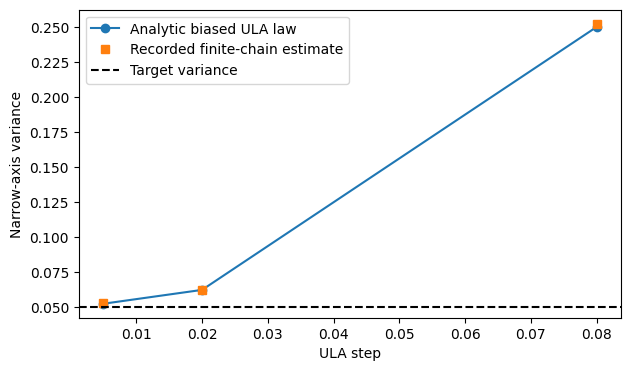

In [3]:
target=load_target("gaussian");eigen=np.linalg.eigvalsh(target.cov)
rows=[]
for eta in [.005,.02,.08]:
 data=numeric(f"gaussian_ula_dispersed_{eta:g}");samples=data["samples"].reshape(-1,2)
 rows.append({"eta":eta,"predicted_narrow_variance":eigen[0]/(1-eta/(2*eigen[0])),"empirical_narrow_variance":np.var((samples-target.mean)@np.array([1.,-1.])/np.sqrt(2))})
table=pd.DataFrame(rows);display(table)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(table.eta,table.predicted_narrow_variance,"o-",label="Analytic biased ULA law");ax.plot(table.eta,table.empirical_narrow_variance,"s",label="Recorded finite-chain estimate");ax.axhline(eigen[0],ls="--",color="black",label="Target variance");ax.set(xlabel="ULA step",ylabel="Narrow-axis variance");ax.legend();plt.show()

## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.